In [1]:
import numpy as np
import csv
import matplotlib.pyplot as plt
plt.rcParams['font.family'] ='Times New Roman'
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.rm'] = 'Times New Roman'  # 设置正常文本的字体
plt.rcParams['mathtext.it'] = 'Times New Roman:italic'  # 设置斜体文本的字体
plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'  # 设置粗体文本的字体

In [2]:
xi=0.9375
Z1=1+np.power(1-xi**2, 1/3)*(np.power(1+xi, 1/3) + np.power(1-xi, 1/3))
Z2=np.sqrt(3*xi**2+Z1**2)
r_ISCO=3+Z2-np.sqrt((3-Z1)*(3+Z1+2*Z2))
Z1,Z2,r_ISCO
# (1+np.sqrt(1+xi))**2

(np.float64(1.813103315975648),
 np.float64(2.4339396838052276),
 np.float64(2.0442013096463136))

In [3]:
filename = '../NormR.csv'


# 打开CSV文件并读取
with open(filename, mode='r') as file:
    reader = csv.reader(file)
    data = list(reader)  # 将CSV内容读入到一个列表中
    
    alpha_values = []
    r_values = []
    R_values = []
    
    # 解析CSV内容
    for row in data:
        alpha_values.append(float(row[0]))  # 第一列：alpha值
        r_values.append(float(row[1]))  # 第二列：r值
        R_values.append(float(row[2]))  # 第三列：R值

    # 将数据转换为numpy数组
    alpha_values = np.array(alpha_values)
    r_values = np.array(r_values)
    R_values = np.array(R_values)

    # 由于alpha有38个值，r有490个值
    # 每一组（alpha, r）应该对应一个R值
    alpha_indices = np.unique(alpha_values)
    r_indices = np.unique(r_values)

    R_data= np.zeros((len(alpha_indices), len(r_indices),3))
    R_data[:,:,0]=alpha_values.reshape(len(alpha_indices), len(r_indices))
    R_data[:,:,1]=r_values.reshape(len(alpha_indices), len(r_indices))
    R_data[:,:,2]=R_values.reshape(len(alpha_indices), len(r_indices))

# 输出结果，查看数组
print(R_data)


[[[9.00000000e-02 1.00000000e+00 0.00000000e+00]
  [9.00000000e-02 1.10000000e+00 0.00000000e+00]
  [9.00000000e-02 1.20000000e+00 0.00000000e+00]
  ...
  [9.00000000e-02 2.40700000e+02 1.00000000e+00]
  [9.00000000e-02 2.40800000e+02 9.99999941e-01]
  [9.00000000e-02 2.40900000e+02 9.99999702e-01]]

 [[1.00000000e-01 1.00000000e+00 0.00000000e+00]
  [1.00000000e-01 1.10000000e+00 0.00000000e+00]
  [1.00000000e-01 1.20000000e+00 0.00000000e+00]
  ...
  [1.00000000e-01 2.40700000e+02 9.78419967e-01]
  [1.00000000e-01 2.40800000e+02 9.78326618e-01]
  [1.00000000e-01 2.40900000e+02 9.78233099e-01]]

 [[1.10000000e-01 1.00000000e+00 0.00000000e+00]
  [1.10000000e-01 1.10000000e+00 0.00000000e+00]
  [1.10000000e-01 1.20000000e+00 0.00000000e+00]
  ...
  [1.10000000e-01 2.40700000e+02 9.18125512e-01]
  [1.10000000e-01 2.40800000e+02 9.17943118e-01]
  [1.10000000e-01 2.40900000e+02 9.17760595e-01]]

 ...

 [[2.90000000e-01 1.00000000e+00 0.00000000e+00]
  [2.90000000e-01 1.10000000e+00 0.0000

In [8]:


def plot_R_r_curves(data):
    """
    绘制不同alpha对应的R-r曲线。
    
    参数：
    data: 二维数组，每个元素data[alpha_index][r_index]包含[alpha, r, R]
    """
    # 获取 alpha 和 r 的维度
    alpha_size, r_size,_ = data.shape
    
    # 设置绘图风格，去除网格背景
    plt.style.use('seaborn-v0_8-white')  # 选择不带网格的简洁样式
    
    plt.rcParams['font.family'] ='Times New Roman'
    plt.rcParams['mathtext.fontset'] = 'custom'
    plt.rcParams['mathtext.rm'] = 'Times New Roman'  # 设置正常文本的字体
    plt.rcParams['mathtext.it'] = 'Times New Roman:italic'  # 设置斜体文本的字体
    plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'  # 设置粗体文本的字体
    
    # 创建一个图形和坐标轴
    fig, ax = plt.subplots(figsize=(8, 6))
    
    # 选择几个 alpha 值绘制曲线
    selected_alphas = [0.1,0.15,0.2,0.25,0.3]  # 你可以根据需要调整
    colors = plt.cm.viridis(np.linspace(0, 1, len(selected_alphas)))

    for i, alpha in enumerate(selected_alphas):
        # 找到对应的 alpha 索引
        alpha_index = np.argmin(np.abs(np.array([data[alpha_idx, 0][0] for alpha_idx in range(alpha_size)]) - alpha))

        # 获取 r 和 R 值
        r_values = [data[alpha_index, r_idx][1] for r_idx in range(r_size)][4:490]
        R_values = [data[alpha_index, r_idx][2] for r_idx in range(r_size)][4:490]

        # 绘制 R-r 曲线
        ax.plot(r_values, R_values, label=rf'$\alpha = {alpha:.3f}$', color=colors[i], lw=3)

    # 在 r=6 处添加一条竖线并标注 ring
    ax.axvline(6, color='red', linestyle='--', linewidth=2)
    ax.text(6, ax.get_ylim()[1]*0.9, 'ring', rotation=90, va='top', ha='right', fontsize=20,color='red')

    # 添加标签和标题
    ax.set_xlabel('$r/r_g$', fontsize=28)
    ax.set_ylabel(r'$R_{211}/R_{\rm max}$', fontsize=28)
    ax.set_title(r'Axion Radial Function $R_{211}(r)$', fontsize=30,pad=13)

    # 设置坐标轴的刻度和字体
    ax.tick_params(axis='both', which='major', labelsize=22)

    # 添加图例，将其放置到右下角
    ax.legend(title='', title_fontsize=20, fontsize=20, loc='best')

    # 美化图表
    plt.tight_layout()


    plt.savefig("images/Axion Radial Function/different alpha.png", dpi=300, bbox_inches='tight')
    # 显示图表
    # plt.show()
    


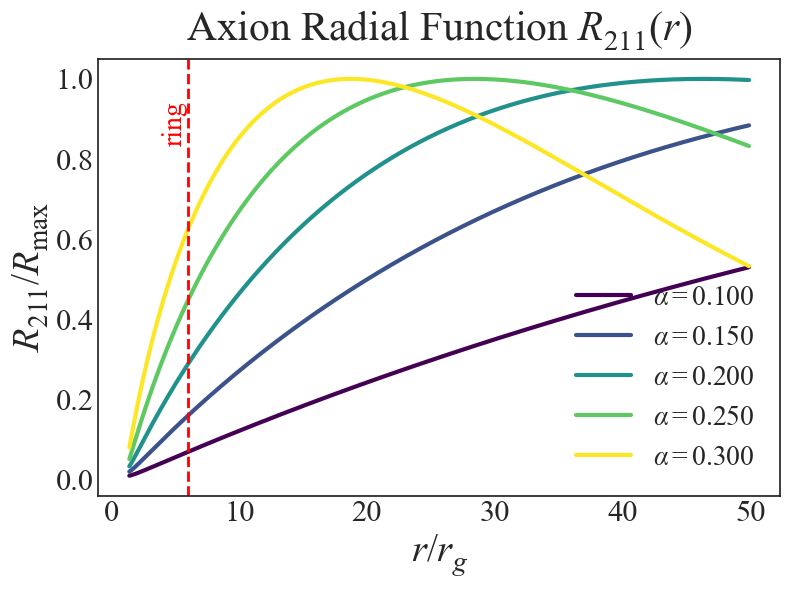

In [9]:
plot_R_r_curves(R_data)

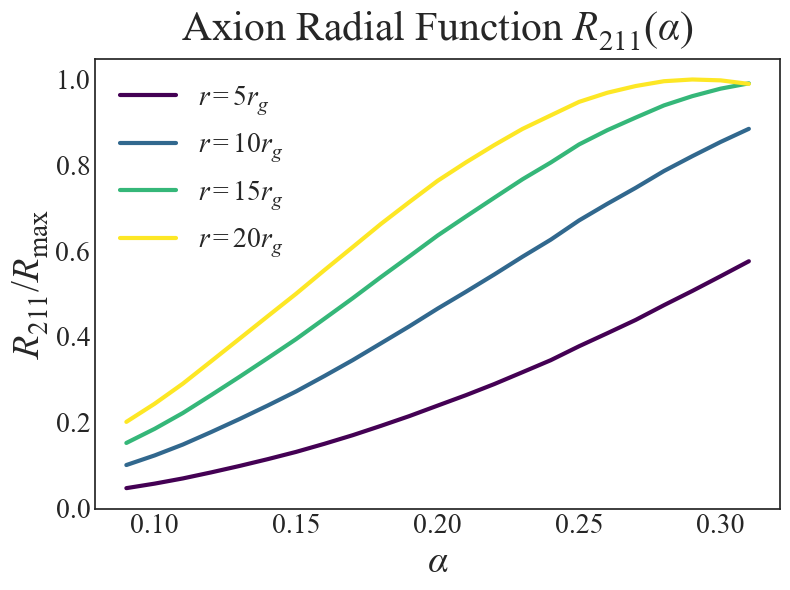

In [28]:
# 在最后一个空 Code Cell 中添加

plt.style.use('seaborn-v0_8-white')
plt.rcParams['font.family'] ='Times New Roman'
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.rm'] = 'Times New Roman'      # 设置正常文本的字体
plt.rcParams['mathtext.it'] = 'Times New Roman:italic' # 设置斜体文本的字体
plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'   # 设置粗体文本的字体

def plot_R_alpha_curves(data):
    """
    绘制同一个 r 下，不同 alpha 对应的 R/R_max 曲线。
    参数：
      data: 形状为 (alpha_size, r_size, 3) 的数组，
            每个元素 [i,j] 包含 [alpha, r, R]
    """
    alpha_size, r_size, _ = data.shape

    # 提取 alpha 和 r 的所有取值
    alpha_values = data[:, 0, 0]
    r_values     = data[0, :, 1]

    # 全局最大 R 用于归一化
    R_max = np.max(data[:,:,2],axis=1)
    R_normed= data[:,:,2] / R_max[:, np.newaxis]

    # 要绘制的 r 值
    selected_rs = [5, 10, 15, 20]
    colors = plt.cm.viridis(np.linspace(0, 1, len(selected_rs)))

    # 创建图形和坐标轴
    fig, ax = plt.subplots(figsize=(8, 6))
    for i, r in enumerate(selected_rs):
        # 找到最接近的 r 索引
        r_idx = np.argmin(np.abs(r_values - r))
        ax.plot(alpha_values, R_normed[:, r_idx],
                label=rf'$r={r} r_g$',
                color=colors[i], lw=3)

    ax.set_xlabel(r'$\alpha$', fontsize=28)
    ax.set_ylabel(r'$R_{211}/R_{\rm max}$', fontsize=28)
    ax.set_title(r'Axion Radial Function $R_{211}(\alpha)$', fontsize=30,pad=13)
    ax.tick_params(axis='both', which='major', labelsize=20)
    ax.legend(fontsize=20, loc='best')
    plt.tight_layout()
    plt.savefig("images/Axion Radial Function/different r.png", dpi=300, bbox_inches='tight')

# 调用并绘图
plot_R_alpha_curves(R_data)